In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric.nn as pyg_nn
import torch_geometric.utils as pyg_utils

import time
from datetime import datetime

import networkx as nx
import numpy as np
import torch.optim as optim

from torch_geometric.datasets import TUDataset
from torch_geometric.datasets import Planetoid 
from torch_geometric.data import DataLoader

import torch_geometric.transforms as T

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [5]:
import pandas as pd

data_folder = "../data/datos_imputados_2023/"

df_dinagua = pd.read_parquet(data_folder+"SL_HIDRO_DINAGUA_SLC_2011_2023.parquet")
df_dinagua.columns = [f"[{station}] {var}" for var, station in df_dinagua.columns]
dates_dinagua = df_dinagua.index

df_inia = pd.read_parquet(data_folder+"SL_MET_INIA_2011_2023.parquet")
df_inia.columns = [f"[{station}] {var}" for var, station in df_inia.columns]
df_inumet = pd.read_parquet(data_folder+"SL_MET_INUMET_SLC_1980_2023.parquet")
df_inumet.columns = [f"[{station}] {var}" for var, station in df_inumet.columns]

df_data_all = pd.concat([df_dinagua, df_inia, df_inumet], axis=1)
df_data_all = df_data_all.loc[dates_dinagua,:]

In [6]:
import re

# Aguas abajo de Florida: '25 de Agosto', 'Mendoza', 'Villa 25 de Mayo', 'Villa Cardal'
connectivity = {
    "Florida (Puente Ruta 5)": ["La Cruz", "San Gabriel", "Cerro Colorado", "Sarandi Grande", "Reboledo", "INIA Las Brujas"],
}
to_predict_station = "Florida (Puente Ruta 5)"
to_predict_col = "[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]"

# Keep only data from important staions (upstream of Florida)

stations_keep = set(connectivity[to_predict_station])

station_map = {
    col: re.match(r"\[(.*?)\]", col).group(1)
    for col in df_data_all.columns
}

cols_keep = [
    col for col, st in station_map.items()
    if st in stations_keep
]

df_data = df_data_all[cols_keep+[to_predict_col]]
df_data = df_data.dropna() # Drop rows with nans
df_data

,[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm],[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]
date,,,,,,,,,,,,,,
2011-01-01,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0,0.347000
2011-01-02,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.5,0.0,0.0,0.0,0.333000
2011-01-03,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0,0.353000
2011-01-04,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0,0.383000
2011-01-05,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0,0.383000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-06-23,0.5,0.5,94.0,92.0,10.6,14.1,6.7,61.4,0.0,0.0,0.0,0.0,0.0,0.352515
2023-06-24,0.5,0.0,96.0,82.9,12.5,15.9,10.1,65.5,0.0,0.2,0.0,0.0,0.2,0.352519
2023-06-25,0.6,0.6,94.0,94.0,12.4,14.2,10.2,83.8,0.0,0.0,0.0,0.0,0.0,0.352540


In [8]:
import torch
from torch_geometric.data import Data

def build_star_timeseries_graph(df, center_col):
    """
    Create a PyG graph where all columns connect to one central column.

    Parameters
    ----------
    df : pandas.DataFrame
        Columns = time series
        Rows = time
    center_col : str
        Column name to connect everything to

    Returns
    -------
    data : torch_geometric.data.Data
        PyG graph object
    """

    # ---- 1. Node mapping ----

    columns = list(df.columns)

    if center_col not in columns:
        raise ValueError("center_col not found in dataframe")

    col_to_idx = {col: i for i, col in enumerate(columns)}

    center_idx = col_to_idx[center_col]

    # ---- 2. Node features ----
    # Each node feature = its full time series

    x = torch.tensor(
        df.values.T,   # shape: [num_nodes, num_timesteps]
        dtype=torch.float
    )

    # ---- 3. Edge construction ----
    # Connect every node to center

    edges = []

    for col, idx in col_to_idx.items():

        if idx == center_idx:
            continue

        # undirected edges
        edges.append([idx, center_idx])
        edges.append([center_idx, idx])

    edge_index = torch.tensor(edges).t().contiguous()

    # ---- 4. Build PyG Data ----

    data = Data(
        x=x,
        edge_index=edge_index
    )

    return data, col_to_idx

In [9]:
data, mapping = build_star_timeseries_graph(
    df_data,
    center_col=to_predict_col
)

print(data)

Data(x=[14, 4561], edge_index=[2, 26])


In [ ]:
torch.Size([2, 26])

In [17]:
data["edge_index"]

tensor([[ 0, 13,  1, 13,  2, 13,  3, 13,  4, 13,  5, 13,  6, 13,  7, 13,  8, 13,
          9, 13, 10, 13, 11, 13, 12, 13],
        [13,  0, 13,  1, 13,  2, 13,  3, 13,  4, 13,  5, 13,  6, 13,  7, 13,  8,
         13,  9, 13, 10, 13, 11, 13, 12]])

In [18]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx

def plot_pyg_graph(data, col_to_idx):

    # Reverse mapping
    idx_to_col = {i: c for c, i in col_to_idx.items()}

    # Convert to networkx
    G = to_networkx(
        data,
        to_undirected=True
    )

    # Labels
    labels = {
        i: idx_to_col[i]
        for i in G.nodes()
    }

    # Layout
    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(10, 10))

    nx.draw(
        G,
        pos,
        with_labels=False,
        node_size=700
    )

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=8
    )

    plt.title("Star Graph (All Nodes Connected to Center)")
    plt.show()

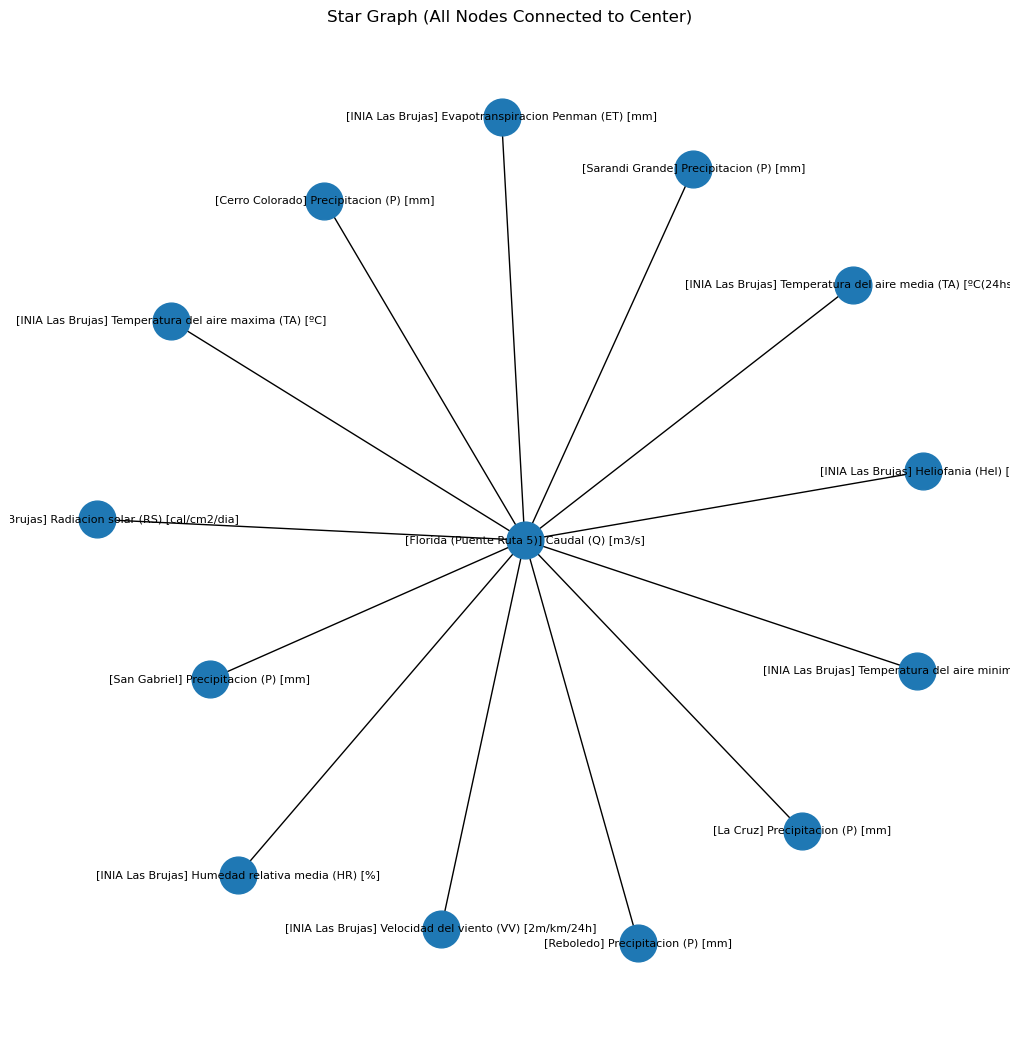

In [21]:
data, mapping = build_star_timeseries_graph(
    df_data,
    center_col=to_predict_col
)

plot_pyg_graph(data, mapping)

---------------------------------------------------------------------

In [ ]:
X = torch.tensor(
    df_data.values,
    dtype=torch.float32
)

target_idx = df_data.columns.get_loc(
    to_predict_col
)

13

In [32]:
import torch

num_nodes = len(df_data.columns)

edges = []

for i in range(num_nodes):

    if i != target_idx:

        edges.append([i, target_idx])

        # Optional reverse edge
        edges.append([target_idx, i])

edge_index = torch.tensor(
    edges,
    dtype=torch.long
).t().contiguous()

In [149]:
class StarGraphDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        X,
        target_idx,
        window=12
    ):
        """
        X:
        [time, num_nodes]
        """

        self.X = X
        self.target_idx = target_idx
        self.window = window

    def __len__(self):

        return len(self.X) - self.window

    def __getitem__(self, idx):

        x_seq = self.X[
            idx : idx + self.window
        ]

        # ADD feature dimension
        x_seq = x_seq.unsqueeze(-1)

        y = self.X[
            idx + self.window,
            self.target_idx
        ]

        return (
            x_seq,              # [T, N, 1]
            y.unsqueeze(0)      # [1]
        )

In [158]:
import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv

class VariableGNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        hidden_dim=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.num_nodes = num_nodes
        self.hidden_dim = hidden_dim

        # Spatial GNN
        self.gcn1 = GCNConv(
            1,
            hidden_dim
        )

        self.gcn2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        # Temporal model
        self.gru = nn.GRU(
            num_nodes * hidden_dim,
            hidden_dim,
            batch_first=True
        )

        # Output
        self.fc = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x_seq):

        """
        x_seq:
        [batch, T, num_nodes, 1]
        """

        B, T, N, F = x_seq.shape

        gnn_out_seq = []

        for t in range(T):

            x_t = x_seq[:, t]

            # flatten batch
            x_t = x_t.reshape(
                B * N,
                F
            )

            x_t = self.gcn1(
                x_t,
                self.edge_index
            ).relu()

            x_t = self.gcn2(
                x_t,
                self.edge_index
            ).relu()

            x_t = x_t.reshape(
                B,
                N * self.hidden_dim
            )

            gnn_out_seq.append(x_t)

        gnn_out_seq = torch.stack(
            gnn_out_seq,
            dim=1
        )

        gru_out, _ = self.gru(
            gnn_out_seq
        )

        last = gru_out[:, -1]

        out = self.fc(last)

        return out

In [ ]:
model = VariableGNN(
    num_nodes=num_nodes,
    edge_index=edge_index,
    hidden_dim=64
)

VariableGNN(
  (gcn1): GCNConv(1, 64)
  (gcn2): GCNConv(64, 64)
  (gru): GRU(896, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=14, bias=True)
)

In [171]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import torch


class MinMaxGNNScaler:

    def __init__(self):

        self.x_scaler = MinMaxScaler()
        self.y_scaler = MinMaxScaler()

    # -------------------------
    # FIT
    # -------------------------

    def fit(self, X, y):

        """
        X:
        [samples, T, num_nodes, 1]

        y:
        [samples, 1]
        """

        n, T, N, F = X.shape

        # Flatten time + samples
        X_flat = X.reshape(
            n * T,
            N
        )

        self.x_scaler.fit(X_flat)

        self.y_scaler.fit(y)

    # -------------------------
    # TRANSFORM
    # -------------------------

    def transform(self, X, y=None):

        n, T, N, F = X.shape

        X_flat = X.reshape(
            n * T,
            N
        )

        X_scaled = self.x_scaler.transform(
            X_flat
        )

        X_scaled = X_scaled.reshape(
            n,
            T,
            N,
            1
        )

        if y is not None:

            y_scaled = self.y_scaler.transform(
                y
            )

            return X_scaled, y_scaled

        return X_scaled

    # -------------------------
    # INVERSE TRANSFORM y
    # -------------------------

    def inverse_y(self, y_scaled):

        return self.y_scaler.inverse_transform(
            y_scaled
        )

In [161]:
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn

# TARGET INDEX FROM COLUMN
target_idx = df_data.columns.get_loc(
    to_predict_col
)

dataset = StarGraphDataset(
    X,
    target_idx,
    window=12
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

model = VariableGNN(
    num_nodes=num_nodes,
    edge_index=edge_index
)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

loss_fn = nn.MSELoss()

for epoch in range(5):

    model.train()

    total_loss = 0

    for x_seq, y in loader:

        pred_target = model(
            x_seq
        )

        loss = loss_fn(
            pred_target,
            y
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        epoch,
        total_loss / len(loader)
    )

0 0.005367425707451215
1 0.00023121321595732247
2 8.382986163604875e-05
3 2.6590483342887464e-05
4 3.7574503735683903e-06


In [164]:
import torch
import matplotlib.pyplot as plt

model.eval()

preds = []
targets = []

with torch.no_grad():

    for x_seq, y in loader:

        pred_target = model(x_seq)

        preds.append(
            pred_target.squeeze()
        )

        targets.append(
            y.squeeze()
        )

preds = torch.cat(preds).cpu()
targets = torch.cat(targets).cpu()

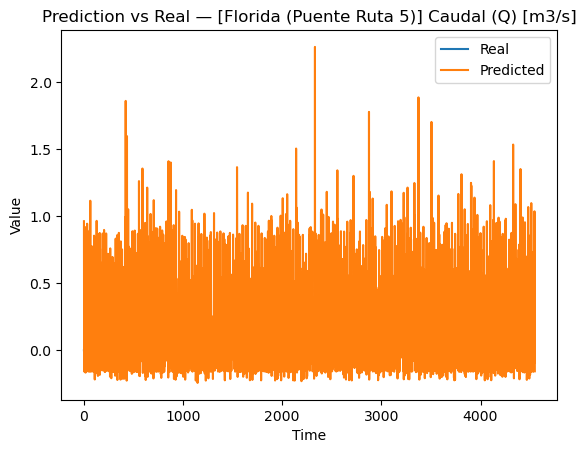

In [156]:
plt.figure()

plt.plot(
    targets.numpy(),
    label="Real"
)

plt.plot(
    preds.numpy(),
    label="Predicted"
)

plt.legend()

plt.title(
    f"Prediction vs Real — {to_predict_col}"
)

plt.xlabel("Time")

plt.ylabel("Value")

plt.show()

-------

In [ ]:
import numpy as np
import torch
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

# Model pipeline with minmax transformation
class MinMaxGNNPipeline:

    def __init__(
        self,
        model,
        batch_size=32
    ):
        self.model = model

        self.x_scaler = MinMaxScaler()
        self.y_scaler = MinMaxScaler()

        self.batch_size = batch_size

    # SCALERS
    def _fit_scalers(self, X, y):

        """
        X:
        [samples, T, num_nodes, 1]

        y:
        [samples, num_nodes]
        """

        n, T, N, F = X.shape

        # Flatten time dimension
        X_flat = X.reshape(
            n * T,
            N
        )

        self.x_scaler.fit(X_flat)

        self.y_scaler.fit(y)

    def _transform_X(self, X):

        n, T, N, F = X.shape

        X_flat = X.reshape(
            n * T,
            N
        )

        X_scaled = self.x_scaler.transform(
            X_flat
        )

        X_scaled = X_scaled.reshape(
            n,
            T,
            N,
            1
        )

        return torch.tensor(
            X_scaled,
            dtype=torch.float32
        )


    def _transform_y(self, y):

        y_scaled = self.y_scaler.transform(
            y
        )

        return torch.tensor(
            y_scaled,
            dtype=torch.float32
        )

    def _inverse_y(self, y):

        y_np = y.detach().cpu().numpy()

        return self.y_scaler.inverse_transform(
            y_np
        )


    # FIT
    def fit(
        self,
        X_train,
        y_train,
        optimizer,
        criterion,
        epochs=5,
        X_val=None,
        y_val=None
    ):

        # Fit scalers
        self._fit_scalers(
            X_train,
            y_train
        )

        # Transform data
        X_train = self._transform_X(X_train)
        y_train = self._transform_y(y_train)

        train_dataset = TensorDataset(
            X_train,
            y_train
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=self.batch_size,
            shuffle=True
        )


        # Validation loader
        if X_val is not None:

            X_val = self._transform_X(X_val)
            y_val = self._transform_y(y_val)

            val_dataset = TensorDataset(
                X_val,
                y_val
            )

            val_loader = DataLoader(
                val_dataset,
                batch_size=self.batch_size,
                shuffle=False
            )

        else:

            val_loader = None


        # TRAIN LOOP
        for epoch in range(epochs):

            self.model.train()

            train_loss = 0

            for x_seq, y in train_loader:

                pred = self.model(
                    x_seq
                )

                loss = criterion(
                    pred,
                    y
                )

                optimizer.zero_grad()

                loss.backward()

                optimizer.step()

                train_loss += loss.item()

            train_loss /= len(train_loader)


            # VALIDATION
            if val_loader is not None:

                self.model.eval()

                val_loss = 0

                with torch.no_grad():

                    for x_seq, y in val_loader:

                        pred = self.model(
                            x_seq
                        )

                        loss = criterion(
                            pred,
                            y
                        )

                        val_loss += loss.item()

                val_loss /= len(val_loader)

                print(
                    f"Epoch {epoch} | "
                    f"Train {train_loss:.5f} | "
                    f"Val {val_loss:.5f}"
                )

            else:

                print(
                    f"Epoch {epoch} | "
                    f"Train {train_loss:.5f}"
                )


    # PREDICTION
    def predict(self, X):

        self.model.eval()

        X = self._transform_X(X)

        with torch.no_grad():

            preds_scaled = self.model(
                X
            )

        preds = self._inverse_y(
            preds_scaled
        )

        return preds

In [95]:
# ALL DATA
X = torch.tensor(
    df_data.values,
    dtype=torch.float32
)

n_total = len(X)

train_ratio = 0.7
val_ratio = 0.10

train_end = int(n_total * train_ratio)
val_end = int(n_total * (train_ratio + val_ratio))

X_train = X[:train_end]
X_val   = X[train_end:val_end]
X_test  = X[val_end:]

X.shape

torch.Size([4561, 14])

In [104]:
data, mapping = build_star_timeseries_graph(
    df_data,
    center_col=to_predict_col
)

data["x"].shape[0]

14

In [123]:
def build_windows(X, Y, window_size):
    """
    X: (samples, features)
    Y: (samples, 1)

    Returns:
    Xw: (num_windows, T, N, 1)
    Yw: (num_windows, 1)
    """

    X_np = X.numpy()
    Y_np = Y.numpy()

    windows = []
    targets = []

    for i in range(len(X_np) - window_size):

        x_win = X_np[i:i + window_size]

        # reshape → (T, N, 1)
        x_win = x_win[:, :, None]

        y_target = Y_np[i + window_size]

        windows.append(x_win)
        targets.append(y_target)

    Xw = torch.tensor(windows, dtype=torch.float32)
    Yw = torch.tensor(targets, dtype=torch.float32)

    return Xw, Yw

In [142]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# BUILD GRAPH
# =========================

data, mapping = build_star_timeseries_graph(
    df_data,
    center_col=to_predict_col
)

edge_index = data["edge_index"]

num_nodes = df_data.shape[1]

# =========================
# BUILD INPUT WITH MASKED TARGET
# =========================

X_df = df_data.copy()

target_idx = X_df.columns.get_loc(
    to_predict_col
)

# MASK TARGET NODE INPUT
X_df.iloc[:, target_idx] = 0.0

X = torch.tensor(
    X_df.values,
    dtype=torch.float32
)

Y = torch.tensor(
    df_data.iloc[:, target_idx].values,
    dtype=torch.float32
).unsqueeze(1)

# =========================
# WINDOWS
# =========================

window_size = 12

Xw, Yw = build_windows(
    X,
    Y,
    window_size
)

Xw = Xw.unsqueeze(-1)

print("Xw:", Xw.shape)
print("Yw:", Yw.shape)

# =========================
# TRAIN / VAL / TEST SPLIT
# (TIME SERIES SAFE)
# =========================

train_ratio = 0.6
test_ratio = 0.2
val_ratio = 0.2

# First split: train+val vs test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    Xw,
    Yw,
    test_size=test_ratio,
    shuffle=False
)

# Second split: train vs val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=val_ratio / (train_ratio + val_ratio),
    shuffle=False
)

# =========================
# MODEL
# =========================

model = VariableGNN(
    num_nodes=num_nodes,
    edge_index=edge_index
)

# =========================
# TRAINING SETUP
# =========================

epochs = 5

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

criterion = nn.MSELoss()

# =========================
# PIPELINE TRAIN
# =========================

model_pipeline = MinMaxGNNPipeline(model)

model_pipeline.fit(
    X_train,
    y_train,
    optimizer,
    criterion,
    epochs=epochs,
    X_val=X_val,
    y_val=y_val
)

Xw: torch.Size([4549, 12, 14, 1, 1])
Yw: torch.Size([4549, 1])


ValueError: too many values to unpack (expected 4)

In [151]:
import torch
import torch.nn as nn
import torch.optim as optim

# --- Parameters ---
epochs =5

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

best_val_loss = float("inf")

for epoch in range(50):

    # TRAIN
    model.train()

    train_loss = 0

    for x_seq, y in train_loader:

        pred = model(x_seq)

        pred_target = pred[:, target_idx]

        loss = loss_fn(
            pred_target,
            y
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # VALIDATION
    model.eval()

    val_loss = 0

    with torch.no_grad():

        for x_seq, y in val_loader:

            pred = model(x_seq)

            pred_target = pred[:, target_idx]

            loss = loss_fn(
                pred_target,
                y
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch} | "
        f"Train {train_loss:.5f} | "
        f"Val {val_loss:.5f}"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_model.pt"
        )

Epoch 0 | Train 0.00122 | Val 0.00046


KeyboardInterrupt: 

In [76]:
model.load_state_dict(
    torch.load("best_model.pt")
)

<All keys matched successfully>

In [77]:
model.eval()

preds = []
targets = []

with torch.no_grad():

    for x_seq, y in test_loader:

        pred = model(x_seq)

        pred_target = pred[:, target_idx]

        preds.append(pred_target)

        targets.append(y)

preds = torch.cat(preds)
targets = torch.cat(targets)

In [83]:
preds.shape

torch.Size([901])

In [81]:
preds_rev = scaler.inverse_transform(preds)
targets_rev = scaler.inverse_transform(targets)


mse = torch.mean(
    (preds_rev - targets_rev) ** 2
)

rmse = torch.sqrt(mse)

mae = torch.mean(
    torch.abs(preds_rev - targets_rev)
)

# R² score
ss_res = torch.sum(
    (targets_rev - preds_rev) ** 2
)

ss_tot = torch.sum(
    (targets_rev - torch.mean(targets_rev)) ** 2
)

r2 = 1 - ss_res / ss_tot

print("\nTest Results:")
print("RMSE:", rmse.item())
print("MAE:", mae.item())
print("R2:", r2.item())

ValueError: Expected 2D array, got 1D array instead:
array=[ 2.03775764e-02  5.19266725e-03  4.40067053e-03  6.13310933e-03
  8.61060619e-03  3.96877527e-03  4.46692109e-03  5.33813238e-03
  2.94041336e-02  1.63627565e-02  1.20088160e-02  1.00334883e-02
  9.73039865e-03  9.37402248e-03  8.68633389e-03  9.54589248e-03
  8.02925229e-03  7.42089748e-03  7.13434815e-03  1.03476048e-02
  4.06694412e-03  4.26262617e-04 -1.65474415e-03  1.89048052e-02
  9.56296921e-03  1.32722259e-02  1.04709566e-02  5.37385941e-02
  2.16844082e-02  1.77059472e-02  1.86368525e-02  1.89985335e-02
  1.91940963e-02  2.09692419e-02  2.18836665e-02  1.93851590e-02
  1.86823905e-02  1.43280625e-02  1.62134767e-02  1.22077465e-02
  1.15095973e-02  1.32846832e-02  1.15298629e-02  1.19286776e-02
  1.03111267e-02  9.56237316e-03  1.03870928e-02  8.47345591e-03
  7.87237287e-03  7.27671385e-03  7.09164143e-03  6.93017244e-03
  6.43321872e-03  3.91054153e-03  4.11361456e-03  4.54097986e-03
  5.12155890e-03  5.81303239e-0

In [ ]:
preds_rev = scaler.inverse_transform(preds)
targets_rev = scaler.inverse_transform(targets)


mse = torch.mean(
    (preds_rev - targets_rev) ** 2
)

rmse = torch.sqrt(mse)

mae = torch.mean(
    torch.abs(preds_rev - targets_rev)
)

# R² score
ss_res = torch.sum(
    (targets_rev - preds_rev) ** 2
)

ss_tot = torch.sum(
    (targets_rev - torch.mean(targets_rev)) ** 2
)

r2 = 1 - ss_res / ss_tot

print("\nTest Results:")
print("RMSE:", rmse.item())
print("MAE:", mae.item())
print("R2:", r2.item())


Test Results:
RMSE: 0.0197448693215847
MAE: 0.010437623597681522
R2: 0.05637317895889282


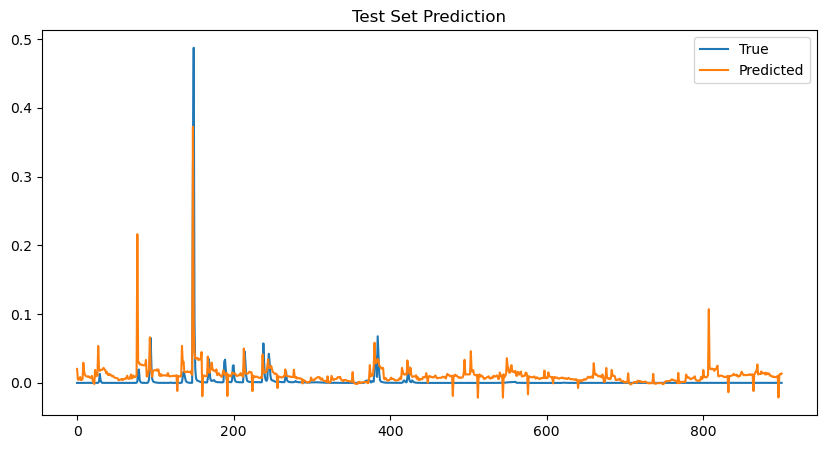

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    targets.numpy(),
    label="True"
)

plt.plot(
    preds.numpy(),
    label="Predicted"
)

plt.legend()

plt.title("Test Set Prediction")

plt.show()

-------

In [ ]:
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

dataset = StarGraphDataset(
    X,
    target_idx,
    window=12
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=True
)

model = VariableGNN(
    num_nodes=num_nodes,
    edge_index=edge_index.to(device)
).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

loss_fn = nn.MSELoss()

for epoch in range(5):

    model.train()

    total_loss = 0

    for x_seq, y in loader:

        x_seq = x_seq.to(device)
        y = y.to(device)

        pred = model(x_seq)

        pred_target = pred[
            :, target_idx
        ]

        loss = loss_fn(
            pred_target,
            y
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch} | Loss {total_loss/len(loader):.6f}"
    )

AcceleratorError: CUDA error: no kernel image is available for execution on the device
Search for `cudaErrorNoKernelImageForDevice' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


---

Epoch 0 | Loss 0.1773
Epoch 1 | Loss 0.1694
Epoch 2 | Loss 0.1674
Epoch 3 | Loss 0.1697
Epoch 4 | Loss 0.1682
Epoch 5 | Loss 0.1686
Epoch 6 | Loss 0.1690
Epoch 7 | Loss 0.1676
Epoch 8 | Loss 0.1678
Epoch 9 | Loss 0.1680
Epoch 10 | Loss 0.1677
Epoch 11 | Loss 0.1815
Epoch 12 | Loss 0.1675
Epoch 13 | Loss 0.1738
Epoch 14 | Loss 0.1671
Epoch 15 | Loss 0.1693
Epoch 16 | Loss 0.1669
Epoch 17 | Loss 0.1665
Epoch 18 | Loss 0.1670
Epoch 19 | Loss 0.1693

TEST RESULTS
MSE: 0.0004379576932001895
R2 : -0.060066853986416424
NSE: -0.060066853986416424


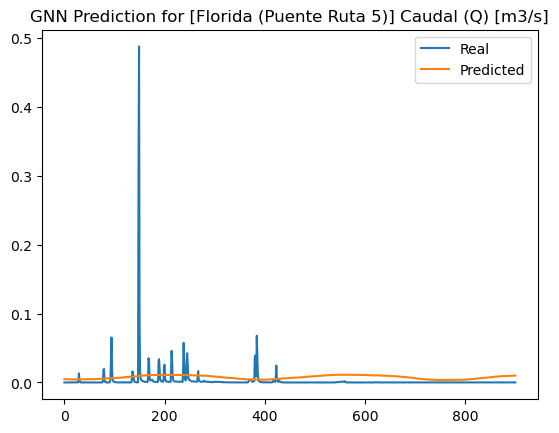

In [291]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

from torch_geometric.nn import GCNConv
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import r2_score as nse_metric


############################################
# 1. BUILD GRAPH FROM DATAFRAME
############################################

def build_star_graph(df, pred_col):

    cols = df.columns.tolist()

    center_idx = cols.index(pred_col)

    edge_list = []

    # connect every node to center node
    for i in range(len(cols)):

        if i != center_idx:

            edge_list.append([i, center_idx])
            edge_list.append([center_idx, i])

    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()

    return edge_index, center_idx


############################################
# 2. DATASET WITH WINDOWING
############################################

class TimeSeriesGraphDataset(Dataset):

    def __init__(
        self,
        data,
        target_idx,
        window=12
    ):

        """
        data:
        numpy array [time, nodes]

        Returns:
        X:
        [window, nodes]

        y:
        scalar (center node)
        """

        self.data = data
        self.target_idx = target_idx
        self.window = window

    def __len__(self):

        return len(self.data) - self.window

    def __getitem__(self, idx):

        X = self.data[
            idx : idx + self.window
        ]

        y = self.data[
            idx + self.window,
            self.target_idx
        ]

        return (
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )


############################################
# 3. BASIC GNN MODEL
############################################

class BasicGNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        hidden_dim=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx


        self.conv1 = GCNConv(
            1,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        self.fc = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        out_seq = []

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            out_seq.append(x_t)

        h = torch.stack(
            out_seq,
            dim=1
        )

        h = h.mean(dim=1)

        center_node_embedding = h[:, self.target_idx, :]

        y = self.fc(
            center_node_embedding
        )

        return y.squeeze()
    
class STGNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        gnn_hidden=64,
        lstm_hidden=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx

        ################################
        # Spatial (GNN)
        ################################

        self.conv1 = GCNConv(
            1,
            gnn_hidden
        )

        self.conv2 = GCNConv(
            gnn_hidden,
            gnn_hidden
        )

        ################################
        # Temporal (LSTM)
        ################################

        self.lstm = nn.LSTM(
            input_size=gnn_hidden,
            hidden_size=lstm_hidden,
            batch_first=True
        )

        ################################
        # Output
        ################################

        self.fc = nn.Linear(
            lstm_hidden,
            1
        )

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        gnn_outputs = []

        ################################
        # Apply GNN at each timestep
        ################################

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            ################################
            # Extract CENTER NODE ONLY
            ################################

            center_emb = x_t[
                :,
                self.target_idx,
                :
            ]

            gnn_outputs.append(
                center_emb
            )

        ################################
        # Stack time
        ################################

        h = torch.stack(
            gnn_outputs,
            dim=1
        )

        ################################
        # LSTM over time
        ################################

        lstm_out, _ = self.lstm(h)

        ################################
        # Last timestep
        ################################

        last_hidden = lstm_out[:, -1, :]

        ################################
        # Predict streamflow
        ################################

        y = self.fc(
            last_hidden
        )

        return y.squeeze()

class STGNNv2(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        gnn_hidden=64,
        lstm_hidden=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx

        ################################
        # Spatial (GNN)
        ################################

        self.conv1 = GCNConv(
            1,
            gnn_hidden
        )

        self.conv2 = GCNConv(
            gnn_hidden,
            gnn_hidden
        )

        ################################
        # Temporal (LSTM)
        ################################

        self.lstm = nn.LSTM(
            input_size=gnn_hidden,
            hidden_size=lstm_hidden,
            batch_first=True
        )

        ################################
        # Output
        ################################

        self.fc = nn.Linear(
            lstm_hidden,
            1
        )

        self.dropout = nn.Dropout(0.3)

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        gnn_outputs = []

        ################################
        # Apply GNN at each timestep
        ################################

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.dropout(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.dropout(x_t) 

            ################################
            # Extract CENTER NODE ONLY
            ################################

            center_emb = x_t[
                :,
                self.target_idx,
                :
            ]

            gnn_outputs.append(
                center_emb
            )

        ################################
        # Stack time
        ################################

        h = torch.stack(
            gnn_outputs,
            dim=1
        )

        ################################
        # LSTM over time
        ################################

        lstm_out, _ = self.lstm(h)

        ################################
        # Last timestep
        ################################

        last_hidden = lstm_out[:, -1, :]

        ################################
        # Predict streamflow
        ################################

        y = self.fc(
            last_hidden
        )

        return y.squeeze()


############################################
# 4. COMPLETE TRAINING WORKFLOW
############################################

def run_gnn_pipeline(
    df,
    pred_col,
    window=12,
    epochs=50,
    batch_size=32
):

    ########################################
    # Normalize
    ########################################

    scaler = MinMaxScaler()

    data = scaler.fit_transform(
        df.values
    )

    ########################################
    # Graph
    ########################################

    edge_index, target_idx = build_star_graph(
        df,
        pred_col
    )

    ########################################
    # Dataset
    ########################################

    dataset = TimeSeriesGraphDataset(
        data,
        target_idx,
        window
    )

    ########################################
    # Train/Test split
    ########################################

    n_total = len(dataset)

    n_train = int(
        0.8 * n_total
    )

    train_ds = torch.utils.data.Subset(
        dataset,
        range(n_train)
    )

    test_ds = torch.utils.data.Subset(
        dataset,
        range(n_train, n_total)
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size
    )

    ########################################
    # Model
    ########################################

    model = BasicGNN(
        num_nodes=df.shape[1],
        edge_index=edge_index,
        target_idx=target_idx
    )
    # model = STGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index,
    #     target_idx=target_idx
    # )


    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    ########################################
    # Training
    ########################################

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for X, y in train_loader:

            optimizer.zero_grad()

            pred = model(X)

            loss = loss_fn(
                pred,
                y
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        if epoch % 1 == 0:

            print(
                f"Epoch {epoch} | Loss {total_loss:.4f}"
            )

    ########################################
    # Testing
    ########################################

    model.eval()

    preds = []
    targets = []

    with torch.no_grad():

        for X, y in test_loader:

            p = model(X)

            preds.extend(
                p.numpy()
            )

            targets.extend(
                y.numpy()
            )

    ########################################
    # Metrics
    ########################################

    mse = mean_squared_error(
        targets,
        preds
    )

    r2 = r2_score(
        targets,
        preds
    )

    nse_test = nse_metric(
        targets,
        preds
    )

    print("\nTEST RESULTS")
    print("MSE:", mse)
    print("R2 :", r2)
    print("NSE:", nse_test)

    ########################################
    # Plot
    ########################################

    plt.figure()

    plt.plot(
        targets,
        label="Real"
    )

    plt.plot(
        preds,
        label="Predicted"
    )

    plt.legend()

    plt.title(
        f"GNN Prediction for {pred_col}"
    )

    plt.show()

    return model


############################################
# 5. RUN
############################################

# Example usage:
#STGNN
model = run_gnn_pipeline(
    df_data,
    pred_col=to_predict_col,
    window=60,
    epochs=20
)

In [292]:
print_model_summary(
    model,
    window=60,
    num_nodes=df_data.shape[1]
)


MODEL STRUCTURE

conv1.bias                               Shape: [64] Params: 64
conv1.lin.weight                         Shape: [64, 1] Params: 64
conv2.bias                               Shape: [64] Params: 64
conv2.lin.weight                         Shape: [64, 64] Params: 4096
fc.weight                                Shape: [1, 64] Params: 64
fc.bias                                  Shape: [1] Params: 1

Total Trainable Parameters: 4353

Testing Forward Pass...
Input shape : torch.Size([1, 60, 14])
Output shape: torch.Size([])
Output ndim: 0
⚠ Unexpected output shape


In [286]:
df_data

,[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm],[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]
date,,,,,,,,,,,,,,
2011-01-01,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0,0.347000
2011-01-02,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.5,0.0,0.0,0.0,0.333000
2011-01-03,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0,0.353000
2011-01-04,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0,0.383000
2011-01-05,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0,0.383000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-06-23,0.5,0.5,94.0,92.0,10.6,14.1,6.7,61.4,0.0,0.0,0.0,0.0,0.0,0.352515
2023-06-24,0.5,0.0,96.0,82.9,12.5,15.9,10.1,65.5,0.0,0.2,0.0,0.0,0.2,0.352519
2023-06-25,0.6,0.6,94.0,94.0,12.4,14.2,10.2,83.8,0.0,0.0,0.0,0.0,0.0,0.352540


In [281]:
df_data

,[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm],[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]
date,,,,,,,,,,,,,,
2011-01-01,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0,0.347000
2011-01-02,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.5,0.0,0.0,0.0,0.333000
2011-01-03,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0,0.353000
2011-01-04,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0,0.383000
2011-01-05,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0,0.383000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-06-23,0.5,0.5,94.0,92.0,10.6,14.1,6.7,61.4,0.0,0.0,0.0,0.0,0.0,0.352515
2023-06-24,0.5,0.0,96.0,82.9,12.5,15.9,10.1,65.5,0.0,0.2,0.0,0.0,0.2,0.352519
2023-06-25,0.6,0.6,94.0,94.0,12.4,14.2,10.2,83.8,0.0,0.0,0.0,0.0,0.0,0.352540


In [266]:
#STGNN

############################################
# 4. COMPLETE TRAINING WORKFLOW
############################################

def run_gnn_pipeline(
    df,
    pred_col,
    window=12,
    epochs=50,
    batch_size=32
):

    ########################################
    # Normalize
    ########################################

    scaler = MinMaxScaler()

    data = scaler.fit_transform(
        df.values
    )

    ########################################
    # Graph
    ########################################

    edge_index, target_idx = build_star_graph(
        df,
        pred_col
    )

    ########################################
    # Dataset
    ########################################

    dataset = TimeSeriesGraphDataset(
        data,
        target_idx,
        window
    )

    ########################################
    # Train/Test split
    ########################################

    n_total = len(dataset)

    n_train = int(
        0.8 * n_total
    )

    train_ds = torch.utils.data.Subset(
        dataset,
        range(n_train)
    )

    test_ds = torch.utils.data.Subset(
        dataset,
        range(n_train, n_total)
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size
    )

    ########################################
    # Model
    ########################################

    # model = BasicGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index
    # )
    model = STGNN(
        num_nodes=df.shape[1],
        edge_index=edge_index,
        target_idx=target_idx
    )


    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    ########################################
    # Training
    ########################################

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for X, y in train_loader:

            optimizer.zero_grad()

            pred = model(X)

            loss = loss_fn(
                pred,
                y
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        if epoch % 1 == 0:

            print(
                f"Epoch {epoch} | Loss {total_loss:.4f}"
            )

    ########################################
    # Testing
    ########################################

    model.eval()

    preds = []
    targets = []

    with torch.no_grad():

        for X, y in test_loader:

            p = model(X)

            preds.extend(
                p.numpy()
            )

            targets.extend(
                y.numpy()
            )

    preds = np.array(preds)
    targets = np.array(targets)

    # Create dummy full arrays
    dummy_pred = np.zeros((len(preds), df.shape[1]))
    dummy_true = np.zeros((len(targets), df.shape[1]))

    # Put values into correct column
    dummy_pred[:, target_idx] = preds.flatten()
    dummy_true[:, target_idx] = targets.flatten()

    # Inverse transform
    preds_inv = scaler.inverse_transform(dummy_pred)[:, target_idx]
    targets_inv = scaler.inverse_transform(dummy_true)[:, target_idx]

    ########################################
    # Metrics
    ########################################

    mse = mean_squared_error(
        targets_inv,
        preds_inv
    )

    r2 = r2_score(
        targets_inv,
        preds_inv
    )

    nse_test = nse_metric(
        targets_inv,
        preds_inv
    )

    print("\nTEST RESULTS")
    print("MSE:", mse)
    print("R2 :", r2)
    print("NSE:", nse_test)

    ########################################
    # Plot
    ########################################

    plt.figure()

    plt.plot(
        targets_inv,
        label="Real"
    )

    plt.plot(
        preds_inv,
        label="Predicted"
    )

    plt.legend()

    plt.title(
        f"GNN Prediction for {pred_col}"
    )

    plt.show()

    return model


############################################
# 5. RUN
############################################

model = run_gnn_pipeline(
    df_data,
    pred_col=to_predict_col,
    window=6,
    epochs=10
)

AttributeError: 'int' object has no attribute 'values'

date
2011-01-01    0.347000
2011-01-02    0.333000
2011-01-03    0.353000
2011-01-04    0.383000
2011-01-05    0.383000
                ...   
2023-06-23    0.352515
2023-06-24    0.352519
2023-06-25    0.352540
2023-06-26    0.352532
2023-06-27    0.352524
Name: [Florida (Puente Ruta 5)] Caudal (Q) [m3/s], Length: 4561, dtype: float64
date
2011-01-01    0.0
2011-01-02    0.0
2011-01-03    0.0
2011-01-04    0.0
2011-01-05    0.0
             ... 
2023-06-23    0.0
2023-06-24    0.0
2023-06-25    0.0
2023-06-26    0.0
2023-06-27    0.0
Name: [Florida (Puente Ruta 5)] Caudal (Q) [m3/s], Length: 4561, dtype: float64
Epoch 0 | Train Loss 16368.8003 | Val Loss 8248.9854
Epoch 1 | Train Loss 16146.2154 | Val Loss 8217.2585
Epoch 2 | Train Loss 16036.2807 | Val Loss 8216.6911
Epoch 3 | Train Loss 16006.2324 | Val Loss 8230.9174
Epoch 4 | Train Loss 15943.7044 | Val Loss 8251.7920
Epoch 5 | Train Loss 15927.8835 | Val Loss 8268.2361
Epoch 6 | Train Loss 15917.5270 | Val Loss 8285.6947
Epoch 7 

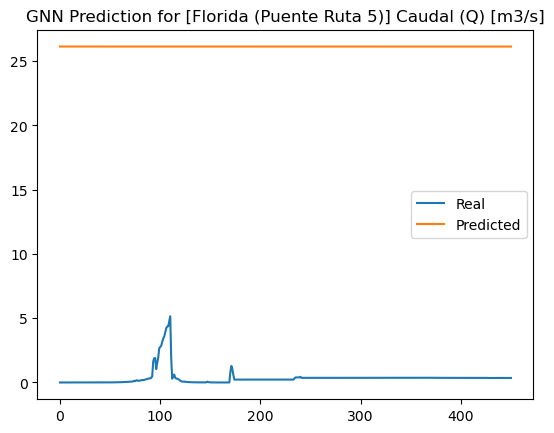

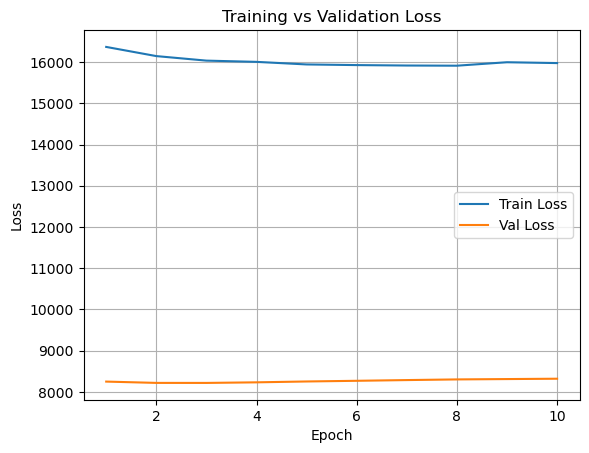

In [265]:
model = run_gnn_pipeline(
    df_data,
    pred_col=to_predict_col,
    window=60,
    epochs=10
)

Epoch 0 | Loss 0.2129
Epoch 1 | Loss 0.1654
Epoch 2 | Loss 0.1634
Epoch 3 | Loss 0.1622
Epoch 4 | Loss 0.1582
Epoch 5 | Loss 0.1564
Epoch 6 | Loss 0.1506
Epoch 7 | Loss 0.1509
Epoch 8 | Loss 0.1520
Epoch 9 | Loss 0.1465
Epoch 10 | Loss 0.1480
Epoch 11 | Loss 0.1429
Epoch 12 | Loss 0.1429
Epoch 13 | Loss 0.1424
Epoch 14 | Loss 0.1375
Epoch 15 | Loss 0.1312
Epoch 16 | Loss 0.1227
Epoch 17 | Loss 0.1334
Epoch 18 | Loss 0.1209
Epoch 19 | Loss 0.1136

TEST RESULTS
MSE: 3454.283225371352
R2 : 0.221357752715319
NSE: 0.221357752715319


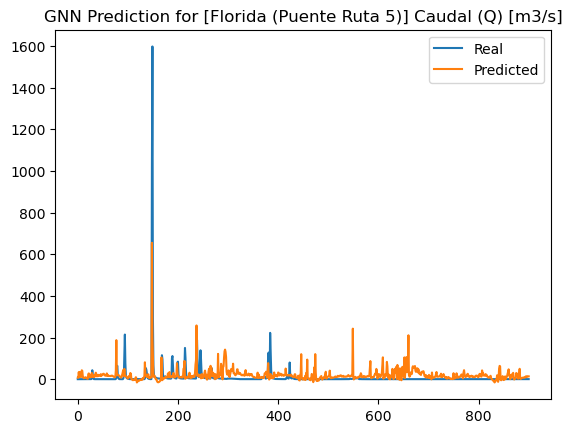

In [189]:
############################################
# 4. COMPLETE TRAINING WORKFLOW
############################################

def run_gnn_pipeline(
    df,
    pred_col,
    window=12,
    epochs=50,
    batch_size=32
):

    ########################################
    # Normalize
    ########################################

    scaler = MinMaxScaler()

    data = scaler.fit_transform(
        df.values
    )

    ########################################
    # Graph
    ########################################

    edge_index, target_idx = build_star_graph(
        df,
        pred_col
    )

    ########################################
    # Dataset
    ########################################

    dataset = TimeSeriesGraphDataset(
        data,
        target_idx,
        window
    )

    ########################################
    # Train/Test split
    ########################################

    n_total = len(dataset)

    n_train = int(
        0.8 * n_total
    )

    train_ds = torch.utils.data.Subset(
        dataset,
        range(n_train)
    )

    test_ds = torch.utils.data.Subset(
        dataset,
        range(n_train, n_total)
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size
    )

    ########################################
    # Model
    ########################################

    # model = BasicGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index
    # )
    # model = STGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index,
    #     target_idx=target_idx
    # )
    model = STGNNv2(
        num_nodes=df.shape[1],
        edge_index=edge_index,
        target_idx=target_idx
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    ########################################
    # Training
    ########################################

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for X, y in train_loader:

            optimizer.zero_grad()

            pred = model(X)

            loss = loss_fn(
                pred,
                y
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        if epoch % 1 == 0:

            print(
                f"Epoch {epoch} | Loss {total_loss:.4f}"
            )

    ########################################
    # Testing
    ########################################

    model.eval()

    preds = []
    targets = []

    with torch.no_grad():

        for X, y in test_loader:

            p = model(X)

            preds.extend(
                p.numpy()
            )

            targets.extend(
                y.numpy()
            )

    ########################################
    # Metrics
    ########################################

    preds = np.array(preds)
    targets = np.array(targets)

    # Create dummy full arrays
    dummy_pred = np.zeros((len(preds), df.shape[1]))
    dummy_true = np.zeros((len(targets), df.shape[1]))

    # Put values into correct column
    dummy_pred[:, target_idx] = preds.flatten()
    dummy_true[:, target_idx] = targets.flatten()

    # Inverse transform
    preds_inv = scaler.inverse_transform(dummy_pred)[:, target_idx]
    targets_inv = scaler.inverse_transform(dummy_true)[:, target_idx]

    ########################################
    # Metrics
    ########################################

    mse = mean_squared_error(
        targets_inv,
        preds_inv
    )

    r2 = r2_score(
        targets_inv,
        preds_inv
    )

    nse_test = nse_metric(
        targets_inv,
        preds_inv
    )

    print("\nTEST RESULTS")
    print("MSE:", mse)
    print("R2 :", r2)
    print("NSE:", nse_test)

    ########################################
    # Plot
    ########################################

    plt.figure()

    plt.plot(
        targets_inv,
        label="Real"
    )

    plt.plot(
        preds_inv,
        label="Predicted"
    )

    plt.legend()

    plt.title(
        f"GNN Prediction for {pred_col}"
    )

    plt.show()

    return model, test_loader

# STGNNv2
model, test_loader = run_gnn_pipeline(
    df_data,
    pred_col=to_predict_col,
    window=60,
    epochs=20
)

Epoch 0 | Loss 0.1819
Epoch 1 | Loss 0.1669
Epoch 2 | Loss 0.1682
Epoch 3 | Loss 0.1653
Epoch 4 | Loss 0.1625
Epoch 5 | Loss 0.1572
Epoch 6 | Loss 0.1545
Epoch 7 | Loss 0.1499
Epoch 8 | Loss 0.1662
Epoch 9 | Loss 0.1549

TEST RESULTS
MSE: 4205.31893184923
R2 : 0.052064127343848465
NSE: 0.052064127343848465


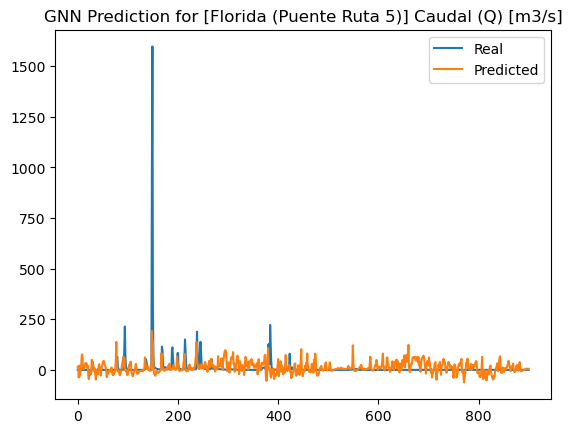

In [8]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

from torch_geometric.nn import GCNConv
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import r2_score as nse_metric


############################################
# 1. BUILD GRAPH FROM DATAFRAME
############################################

def build_star_graph(df, pred_col):

    cols = df.columns.tolist()

    center_idx = cols.index(pred_col)

    edge_list = []

    # connect every node to center node
    for i in range(len(cols)):

        if i != center_idx:

            edge_list.append([i, center_idx])
            edge_list.append([center_idx, i])

    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()

    return edge_index, center_idx


############################################
# 2. DATASET WITH WINDOWING
############################################

class TimeSeriesGraphDataset(Dataset):

    def __init__(
        self,
        data,
        target_idx,
        window=12
    ):

        """
        data:
        numpy array [time, nodes]

        Returns:
        X:
        [window, nodes]

        y:
        scalar (center node)
        """

        self.data = data
        self.target_idx = target_idx
        self.window = window

    def __len__(self):

        return len(self.data) - self.window

    def __getitem__(self, idx):

        X = self.data[
            idx : idx + self.window
        ]

        y = self.data[
            idx + self.window,
            self.target_idx
        ]

        return (
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )


############################################
# 3. BASIC GNN MODEL
############################################

class BasicGNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        hidden_dim=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx


        self.conv1 = GCNConv(
            1,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        self.fc = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        out_seq = []

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            out_seq.append(x_t)

        h = torch.stack(
            out_seq,
            dim=1
        )

        h = h.mean(dim=1)

        center_node_embedding = h[:, self.target_idx, :]

        y = self.fc(
            center_node_embedding
        )

        return y.squeeze()
    
class STGNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        gnn_hidden=64,
        lstm_hidden=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx

        ################################
        # Spatial (GNN)
        ################################

        self.conv1 = GCNConv(
            1,
            gnn_hidden
        )

        self.conv2 = GCNConv(
            gnn_hidden,
            gnn_hidden
        )

        ################################
        # Temporal (LSTM)
        ################################

        self.lstm = nn.LSTM(
            input_size=gnn_hidden,
            hidden_size=lstm_hidden,
            batch_first=True
        )

        ################################
        # Output
        ################################

        self.fc = nn.Linear(
            lstm_hidden,
            1
        )

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        gnn_outputs = []

        ################################
        # Apply GNN at each timestep
        ################################

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            ################################
            # Extract CENTER NODE ONLY
            ################################

            center_emb = x_t[
                :,
                self.target_idx,
                :
            ]

            gnn_outputs.append(
                center_emb
            )

        ################################
        # Stack time
        ################################

        h = torch.stack(
            gnn_outputs,
            dim=1
        )

        ################################
        # LSTM over time
        ################################

        lstm_out, _ = self.lstm(h)

        ################################
        # Last timestep
        ################################

        last_hidden = lstm_out[:, -1, :]

        ################################
        # Predict streamflow
        ################################

        y = self.fc(
            last_hidden
        )

        return y.squeeze()

class STGNNv2(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        target_idx,
        gnn_hidden=64,
        lstm_hidden=64
    ):
        super().__init__()

        self.edge_index = edge_index
        self.target_idx = target_idx

        ################################
        # Spatial (GNN)
        ################################

        self.conv1 = GCNConv(
            1,
            gnn_hidden
        )

        self.conv2 = GCNConv(
            gnn_hidden,
            gnn_hidden
        )

        ################################
        # Temporal (LSTM)
        ################################

        self.lstm = nn.LSTM(
            input_size=gnn_hidden,
            hidden_size=lstm_hidden,
            batch_first=True
        )

        ################################
        # Output
        ################################

        self.fc = nn.Linear(
            lstm_hidden,
            1
        )

        self.dropout = nn.Dropout(0.3)

    def forward(self, x_seq):

        """
        x_seq:
        [batch, window, nodes]
        """

        B, T, N = x_seq.shape

        gnn_outputs = []

        ################################
        # Apply GNN at each timestep
        ################################

        for t in range(T):

            x_t = x_seq[:, t, :]

            x_t = x_t.unsqueeze(-1)

            x_t = self.conv1(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.dropout(x_t)

            x_t = self.conv2(
                x_t,
                self.edge_index
            )

            x_t = torch.relu(x_t)

            x_t = self.dropout(x_t) 

            ################################
            # Extract CENTER NODE ONLY
            ################################

            center_emb = x_t[
                :,
                self.target_idx,
                :
            ]

            gnn_outputs.append(
                center_emb
            )

        ################################
        # Stack time
        ################################

        h = torch.stack(
            gnn_outputs,
            dim=1
        )

        ################################
        # LSTM over time
        ################################

        lstm_out, _ = self.lstm(h)

        ################################
        # Last timestep
        ################################

        last_hidden = lstm_out[:, -1, :]

        ################################
        # Predict streamflow
        ################################

        y = self.fc(
            last_hidden
        )

        return y.squeeze()


############################################
# 4. COMPLETE TRAINING WORKFLOW
############################################

def run_gnn_pipeline(
    df,
    pred_col,
    window=12,
    epochs=50,
    batch_size=32
):

    ########################################
    # Normalize
    ########################################

    scaler = MinMaxScaler()

    data = scaler.fit_transform(
        df.values
    )

    ########################################
    # Graph
    ########################################

    edge_index, target_idx = build_star_graph(
        df,
        pred_col
    )

    ########################################
    # Dataset
    ########################################

    dataset = TimeSeriesGraphDataset(
        data,
        target_idx,
        window
    )

    ########################################
    # Train/Test split
    ########################################

    n_total = len(dataset)

    n_train = int(
        0.8 * n_total
    )

    train_ds = torch.utils.data.Subset(
        dataset,
        range(n_train)
    )

    test_ds = torch.utils.data.Subset(
        dataset,
        range(n_train, n_total)
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size
    )

    ########################################
    # Model
    ########################################

    # model = BasicGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index
    # )
    # model = STGNN(
    #     num_nodes=df.shape[1],
    #     edge_index=edge_index,
    #     target_idx=target_idx
    # )
    model = STGNNv2(
        num_nodes=df.shape[1],
        edge_index=edge_index,
        target_idx=target_idx
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    ########################################
    # Training
    ########################################

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for X, y in train_loader:

            optimizer.zero_grad()

            pred = model(X)

            loss = loss_fn(
                pred,
                y
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        if epoch % 1 == 0:

            print(
                f"Epoch {epoch} | Loss {total_loss:.4f}"
            )

    ########################################
    # Testing
    ########################################

    model.eval()

    preds = []
    targets = []

    with torch.no_grad():

        for X, y in test_loader:

            p = model(X)

            preds.extend(
                p.numpy()
            )

            targets.extend(
                y.numpy()
            )

    ########################################
    # Metrics
    ########################################

    preds = np.array(preds)
    targets = np.array(targets)

    # Create dummy full arrays
    dummy_pred = np.zeros((len(preds), df.shape[1]))
    dummy_true = np.zeros((len(targets), df.shape[1]))

    # Put values into correct column
    dummy_pred[:, target_idx] = preds.flatten()
    dummy_true[:, target_idx] = targets.flatten()

    # Inverse transform
    preds_inv = scaler.inverse_transform(dummy_pred)[:, target_idx]
    targets_inv = scaler.inverse_transform(dummy_true)[:, target_idx]

    ########################################
    # Metrics
    ########################################

    mse = mean_squared_error(
        targets_inv,
        preds_inv
    )

    r2 = r2_score(
        targets_inv,
        preds_inv
    )

    nse_test = nse_metric(
        targets_inv,
        preds_inv
    )

    print("\nTEST RESULTS")
    print("MSE:", mse)
    print("R2 :", r2)
    print("NSE:", nse_test)

    ########################################
    # Plot
    ########################################

    plt.figure()

    plt.plot(
        targets_inv,
        label="Real"
    )

    plt.plot(
        preds_inv,
        label="Predicted"
    )

    plt.legend()

    plt.title(
        f"GNN Prediction for {pred_col}"
    )

    plt.show()

    return model, test_loader

# STGNNv2
model, test_loader = run_gnn_pipeline(
    df_data,
    pred_col=to_predict_col,
    window=60,
    epochs=10
)

In [202]:
# MODEL SUMMARY FUNCTION
def print_model_summary(
    model,
    window,
    num_nodes
):

    print("\nMODEL STRUCTURE\n")

    ################################
    # Parameter Summary
    ################################

    total_params = 0

    for name, param in model.named_parameters():

        if param.requires_grad:

            params = param.numel()

            total_params += params

            print(
                f"{name:40s}"
                f" Shape: {list(param.shape)}"
                f" Params: {params}"
            )

    print("\nTotal Trainable Parameters:", total_params)

    ################################
    # Forward Pass Test
    ################################

    device = next(
        model.parameters()
    ).device

    model.eval()

    dummy_input = torch.randn(
        1,
        window,
        num_nodes
    ).to(device)

    print("\nTesting Forward Pass...")

    with torch.no_grad():

        output = model(
            dummy_input
        )

    print(
        "Input shape :",
        dummy_input.shape
    )

    print(
        "Output shape:",
        output.shape
    )

    print(
        "Output ndim:",
        output.ndim
    )

    ################################
    # Output sanity check
    ################################

    if output.ndim == 1:

        print("✓ Output is scalar per sample")

    elif output.ndim == 2:

        print("✓ Output batch detected")

    else:

        print("⚠ Unexpected output shape")
print_model_summary(
    model,
    window=60,
    num_nodes=df_data.shape[1]
)


MODEL STRUCTURE

conv1.bias                               Shape: [64] Params: 64
conv1.lin.weight                         Shape: [64, 1] Params: 64
conv2.bias                               Shape: [64] Params: 64
conv2.lin.weight                         Shape: [64, 64] Params: 4096
lstm.weight_ih_l0                        Shape: [256, 64] Params: 16384
lstm.weight_hh_l0                        Shape: [256, 64] Params: 16384
lstm.bias_ih_l0                          Shape: [256] Params: 256
lstm.bias_hh_l0                          Shape: [256] Params: 256
fc.weight                                Shape: [1, 64] Params: 64
fc.bias                                  Shape: [1] Params: 1

Total Trainable Parameters: 37633

Testing Forward Pass...
Input shape : torch.Size([1, 60, 14])
Output shape: torch.Size([])
Output ndim: 0
⚠ Unexpected output shape


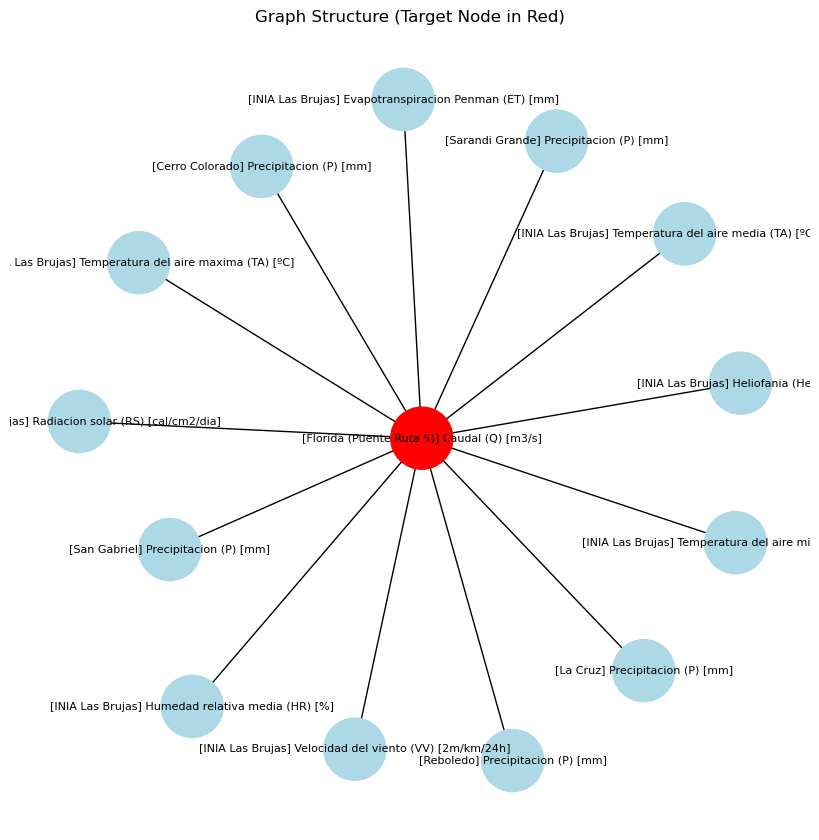

In [204]:
# PLOT GRAPH STRUCTURE

import networkx as nx
import matplotlib.pyplot as plt


def plot_graph_structure(df, edge_index, pred_col):

    cols = df.columns.tolist()

    G = nx.Graph()

    # Add nodes
    for col in cols:

        G.add_node(col)

    # Add edges
    edges = edge_index.t().numpy()

    for i, j in edges:

        G.add_edge(
            cols[i],
            cols[j]
        )

    # Star layout centered at target
    pos = nx.spring_layout(
        G,
        seed=42
    )

    plt.figure(figsize=(8, 8))

    node_colors = []

    for col in cols:

        if col == pred_col:

            node_colors.append("red")

        else:

            node_colors.append("lightblue")

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color=node_colors,
        node_size=2000,
        font_size=8
    )

    plt.title("Graph Structure (Target Node in Red)")

    plt.show()


# CALL AFTER GRAPH CREATION

plot_graph_structure(
    df_data,
    edge_index,
    to_predict_col
)

In [9]:
############################################
# CAPTUM EXPLANATION BLOCK (FULL FIXED)
############################################

from captum.attr import IntegratedGradients
import numpy as np
import matplotlib.pyplot as plt
import torch


def explain_with_captum(
    model,
    test_loader
):

    model.eval()

    ig = IntegratedGradients(model)

    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    ##################################
    # Compute attributions
    ##################################

    for X, y in test_loader:

        X = X.requires_grad_()

        attributions = ig.attribute(
            X,
            target=None
        )

        print(
            "Batch attribution shape:",
            attributions.shape
        )

        attr = attributions.detach().numpy()

        # Absolute values
        attr = np.abs(attr)

        # Store batch
        all_attr.append(attr)

    ##################################
    # Merge all batches
    ##################################

    attr = np.concatenate(
        all_attr,
        axis=0
    )

    print(
        "Merged attribution shape:",
        attr.shape
    )

    ##################################
    # Average across samples
    ##################################

    attr = attr.mean(axis=0)

    # Now:
    # attr shape → [T, N]

    print(
        "Final attribution shape:",
        attr.shape
    )

    ##################################
    # Node Importance
    ##################################

    node_importance = attr.mean(axis=0)

    plt.figure()

    plt.bar(
        np.arange(len(node_importance)),
        node_importance
    )

    plt.title(
        "Node Importance (Integrated Gradients)"
    )

    plt.xlabel("Node index")

    plt.ylabel("Importance")

    plt.show()

    ##################################
    # Sorted Node Importance
    ##################################

    order = np.argsort(
        node_importance
    )[::-1]

    plt.figure()

    plt.bar(
        range(len(order)),
        node_importance[order]
    )

    plt.title(
        "Sorted Node Importance"
    )

    plt.xlabel("Ranked Nodes")

    plt.ylabel("Importance")

    plt.show()

    ##################################
    # Time Importance
    ##################################

    time_importance = attr.mean(axis=1)

    plt.figure()

    plt.plot(
        time_importance
    )

    plt.title(
        "Time-step Importance"
    )

    plt.xlabel("Time Step")

    plt.ylabel("Importance")

    plt.show()

    ##################################
    # Heatmap (MOST IMPORTANT)
    ##################################

    plt.figure()

    plt.imshow(
        attr.T,
        aspect="auto"
    )

    plt.colorbar()

    plt.title(
        "Node-Time Attribution Heatmap"
    )

    plt.xlabel("Time Step")

    plt.ylabel("Node")

    plt.show()

    ##################################
    # Return attribution
    ##################################

    return attr


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attribution shape: torch.Size([32, 60, 14])
Batch attr

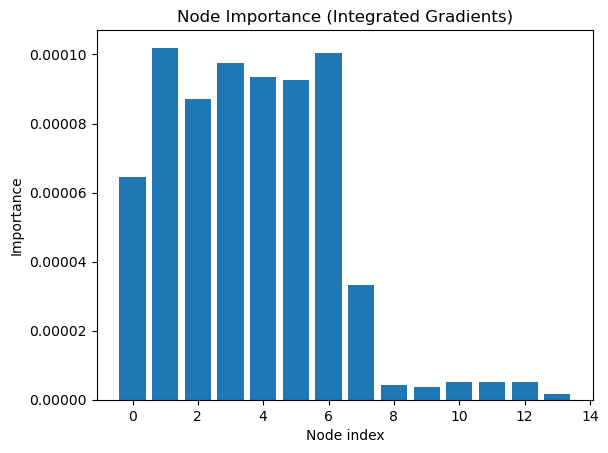

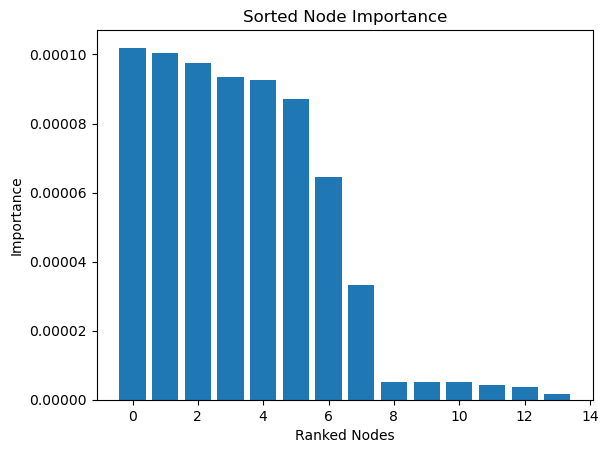

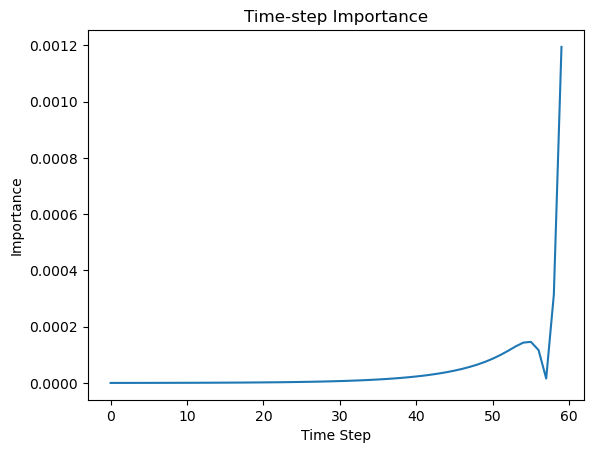

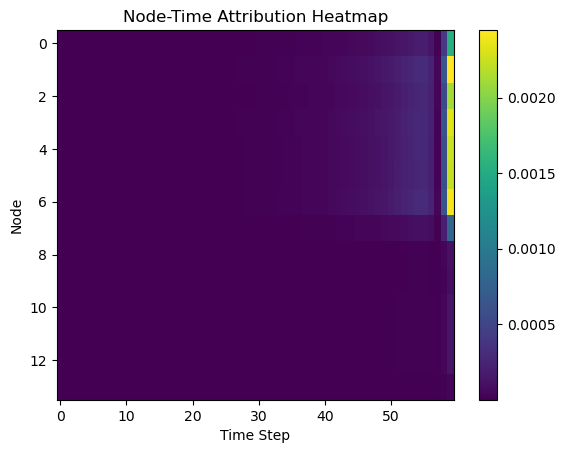

In [10]:
#NEWWWW
attr = explain_with_captum(
    model,
    test_loader
)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attribution shape: torch.Size([32, 12, 14])
Batch attr

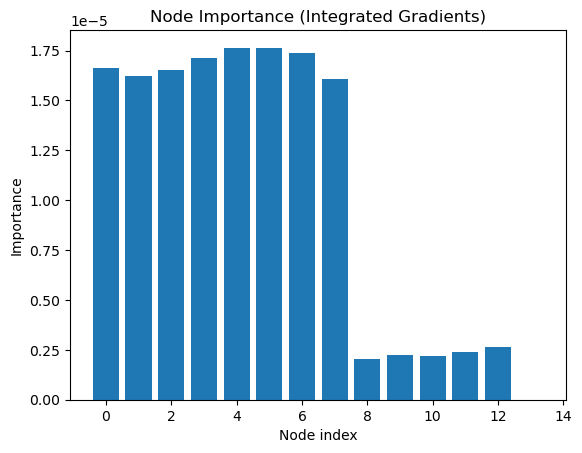

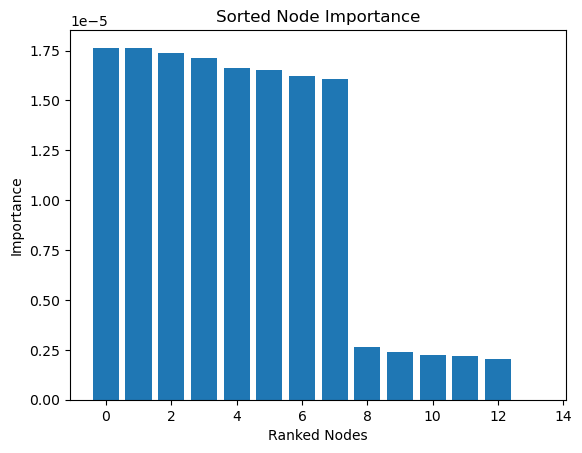

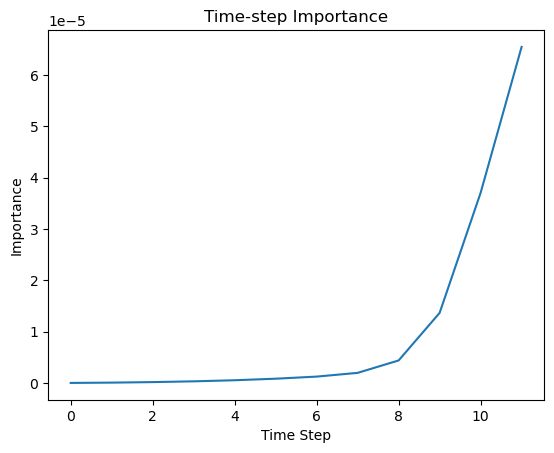

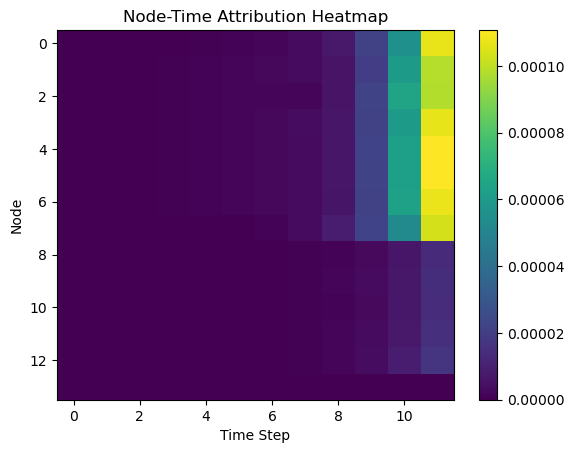

In [ ]:
# OLD (GOOD)
attr = explain_with_captum(
    model,
    test_loader
)

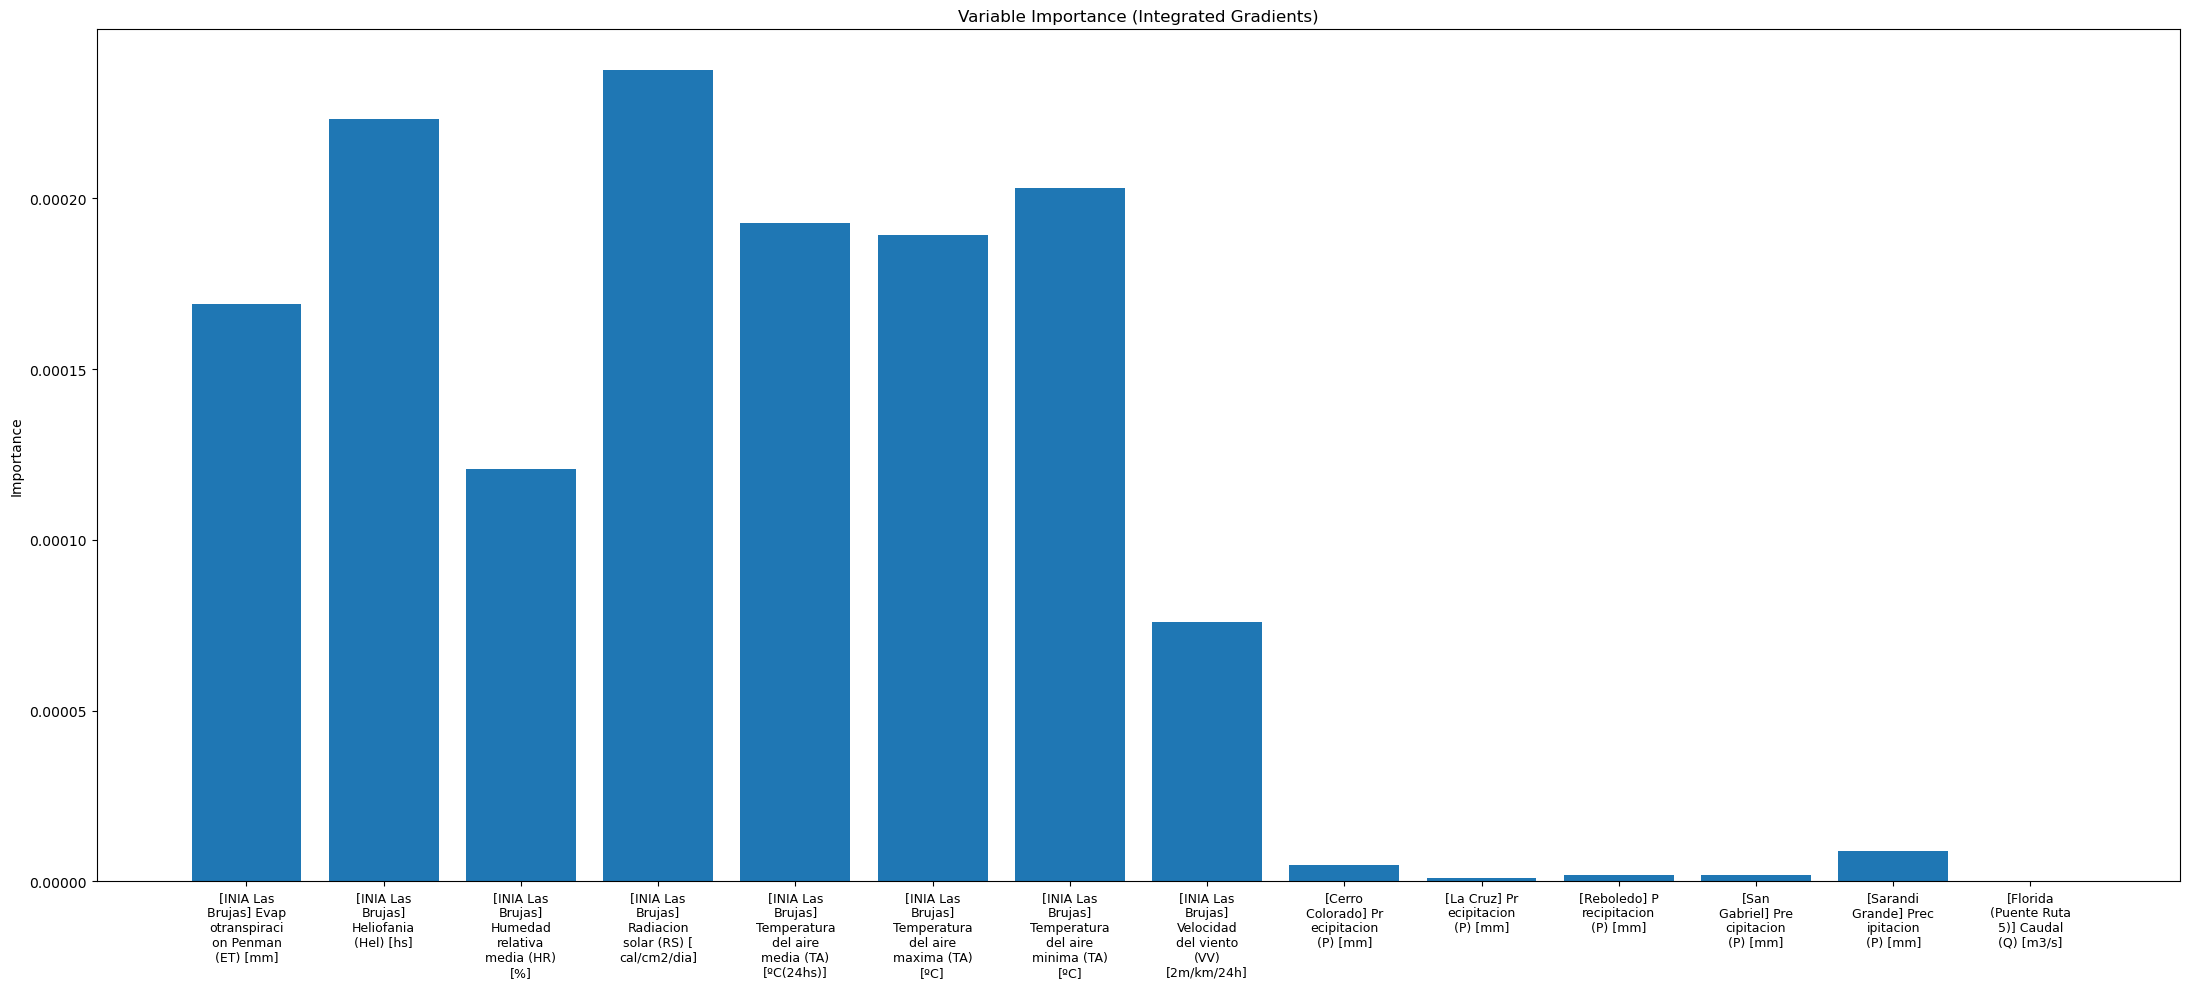


Variable Importance Ranking:

[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia]0.000238
[INIA Las Brujas] Heliofania (Hel) [hs]0.000223
[INIA Las Brujas] Temperatura del aire minima (TA) [ºC]0.000203
[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)]0.000193
[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC]0.000189
[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm]0.000169
[INIA Las Brujas] Humedad relativa media (HR) [%]0.000121
[INIA Las Brujas] Velocidad del viento (VV) /km/24h]0.000076
[Sarandi Grande] Precipitacion (P) [mm]0.000009
[Cerro Colorado] Precipitacion (P) [mm]0.000005
[Reboledo] Precipitacion (P) [mm]0.000002
[San Gabriel] Precipitacion (P) [mm]0.000002
[La Cruz] Precipitacion (P) [mm]0.000001
[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]0.000000


In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from captum.attr import IntegratedGradients


############################################
# MODEL WRAPPER FOR CAPTUM
############################################

class CaptumWrapper(torch.nn.Module):

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):

        out = self.model(x)

        # Convert [batch] → [batch,1]
        return out.unsqueeze(-1)
import textwrap

############################################
# VARIABLE IMPORTANCE PLOT
############################################

def plot_variable_importance_captum(
    model,
    test_loader,
    df,
    device="cpu"
):

    model.eval()

    wrapped_model = CaptumWrapper(
        model
    ).to(device)

    ig = IntegratedGradients(
        wrapped_model
    )

    ################################
    # Get one sample
    ################################

    X_sample, y_sample = next(
        iter(test_loader)
    )

    X_sample = X_sample[:1].to(device)

    baseline = torch.zeros_like(
        X_sample
    ).to(device)

    ################################
    # Compute attribution
    ################################

    attributions, delta = ig.attribute(
        X_sample,
        baselines=baseline,
        return_convergence_delta=True
    )

    ################################
    # Aggregate over time
    ################################

    # Shape:
    # [1, window, nodes]

    attr = attributions.detach().cpu().numpy()[0]

    # Mean over time
    node_importance = np.mean(
        np.abs(attr),
        axis=0
    )

    ################################
    # Plot with variable names
    ################################
    variable_names = df.columns.tolist()

    wrapped_labels = [
        "\n".join(textwrap.wrap(name, 12))
        for name in variable_names
    ]


    plt.figure(figsize=(22, 10))

    plt.bar(
        wrapped_labels,
        node_importance
    )

    plt.xticks(rotation=0, ha="center", fontsize=9)

    plt.title(
        "Variable Importance (Integrated Gradients)"
    )

    plt.ylabel(
        "Importance"
    )

    plt.tight_layout()

    plt.show()

    ################################
    # Print ranked variables
    ################################

    sorted_idx = np.argsort(
        node_importance
    )[::-1]

    print("\nVariable Importance Ranking:\n")

    for i in sorted_idx:

        print(
            f"{variable_names[i]:20s}"
            f"{node_importance[i]:.6f}"
        )

    return node_importance

importance = plot_variable_importance_captum(
    model,
    test_loader,
    df_data,
    device="cpu"
)

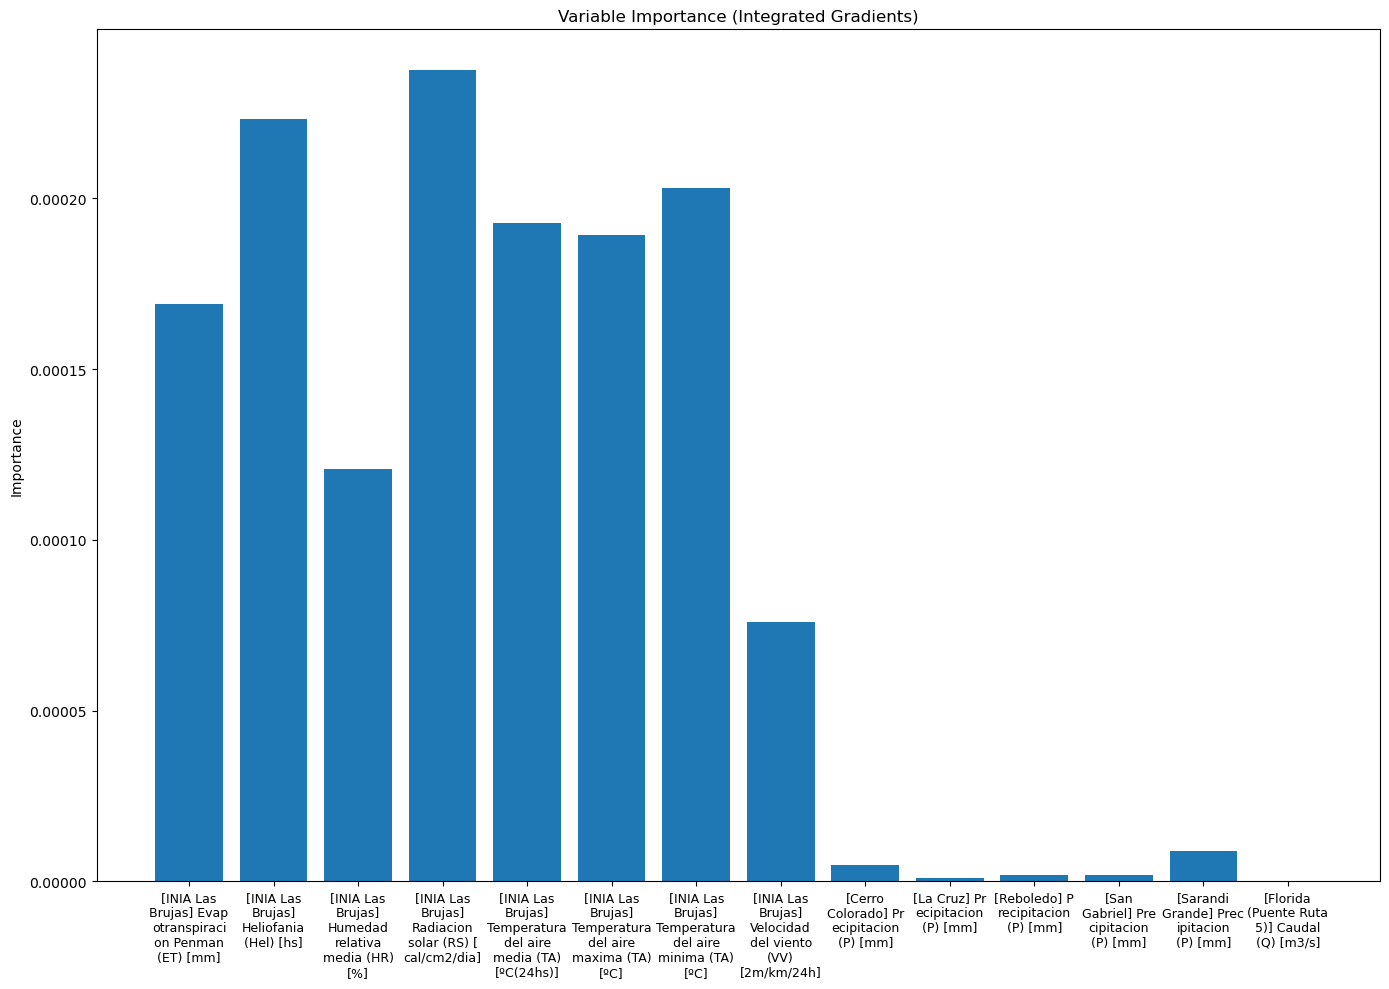


Variable Importance Ranking:

[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia]0.000238
[INIA Las Brujas] Heliofania (Hel) [hs]0.000223
[INIA Las Brujas] Temperatura del aire minima (TA) [ºC]0.000203
[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)]0.000193
[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC]0.000189
[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm]0.000169
[INIA Las Brujas] Humedad relativa media (HR) [%]0.000121
[INIA Las Brujas] Velocidad del viento (VV) /km/24h]0.000076
[Sarandi Grande] Precipitacion (P) [mm]0.000009
[Cerro Colorado] Precipitacion (P) [mm]0.000005
[Reboledo] Precipitacion (P) [mm]0.000002
[San Gabriel] Precipitacion (P) [mm]0.000002
[La Cruz] Precipitacion (P) [mm]0.000001
[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]0.000000


In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from captum.attr import IntegratedGradients


############################################
# MODEL WRAPPER FOR CAPTUM
############################################

class CaptumWrapper(torch.nn.Module):

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):

        out = self.model(x)

        # Convert [batch] → [batch,1]
        return out.unsqueeze(-1)
import textwrap

############################################
# VARIABLE IMPORTANCE PLOT
############################################

def plot_variable_importance_captum(
    model,
    test_loader,
    df,
    device="cpu"
):

    model.eval()

    wrapped_model = CaptumWrapper(
        model
    ).to(device)

    ig = IntegratedGradients(
        wrapped_model
    )

    ################################
    # Get one sample
    ################################

    X_sample, y_sample = next(
        iter(test_loader)
    )

    X_sample = X_sample[:1].to(device)

    baseline = torch.zeros_like(
        X_sample
    ).to(device)

    ################################
    # Compute attribution
    ################################

    attributions, delta = ig.attribute(
        X_sample,
        baselines=baseline,
        return_convergence_delta=True
    )

    ################################
    # Aggregate over time
    ################################

    # Shape:
    # [1, window, nodes]

    attr = attributions.detach().cpu().numpy()[0]

    # Mean over time
    node_importance = np.mean(
        np.abs(attr),
        axis=0
    )

    ################################
    # Plot with variable names
    ################################
    variable_names = df.columns.tolist()

    wrapped_labels = [
        "\n".join(textwrap.wrap(name, 12))
        for name in variable_names
    ]


    plt.figure(figsize=(14, 10))

    plt.bar(
        wrapped_labels,
        node_importance
    )

    plt.xticks(rotation=0, ha="center", fontsize=9)

    plt.title(
        "Variable Importance (Integrated Gradients)"
    )

    plt.ylabel(
        "Importance"
    )

    plt.tight_layout()

    plt.show()

    ################################
    # Print ranked variables
    ################################

    sorted_idx = np.argsort(
        node_importance
    )[::-1]

    print("\nVariable Importance Ranking:\n")

    for i in sorted_idx:

        print(
            f"{variable_names[i]:20s}"
            f"{node_importance[i]:.6f}"
        )

    return node_importance

importance = plot_variable_importance_captum(
    model,
    test_loader,
    df_data,
    device="cpu"
)

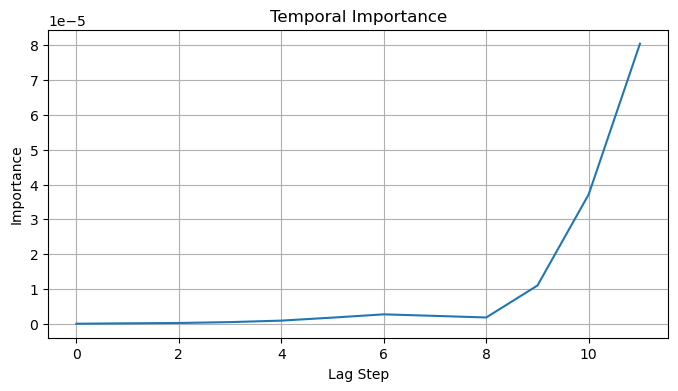

In [221]:
def plot_temporal_importance_captum(
    model,
    test_loader,
    df,
    device="cpu"
):

    model.eval()

    wrapped_model = CaptumWrapper(
        model
    ).to(device)

    ig = IntegratedGradients(
        wrapped_model
    )

    X_sample, _ = next(
        iter(test_loader)
    )

    X_sample = X_sample[:1].to(device)

    baseline = torch.zeros_like(
        X_sample
    ).to(device)

    attributions, _ = ig.attribute(
        X_sample,
        baselines=baseline,
        return_convergence_delta=True
    )

    attr = attributions.detach().cpu().numpy()[0]

    ################################
    # Aggregate over variables
    ################################

    temporal_importance = np.mean(
        np.abs(attr),
        axis=1
    )

    ################################
    # Plot
    ################################

    plt.figure(figsize=(8, 4))

    plt.plot(
        temporal_importance
    )

    plt.title(
        "Temporal Importance"
    )

    plt.xlabel(
        "Lag Step"
    )

    plt.ylabel(
        "Importance"
    )

    plt.grid()

    plt.show()

plot_temporal_importance_captum(
    model,
    test_loader,
    df_data
)

---

**BASELINES**

In [295]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# =========================
# NSE FUNCTION
# =========================
def nse(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)


# =========================
# WINDOWING FUNCTION (12 steps)
# =========================
def create_windows(series, window=12):
    X, y = [], []
    for i in range(len(series) - window):
        X.append(series[i:i+window])
        y.append(series[i+window])
    return np.array(X), np.array(y)


# =========================
# LOAD DATA
# =========================
# assume df has column "streamflow"
# df = pd.read_csv("your_data.csv")
# series = df["streamflow"].values

window = 60
X, y = create_windows(df_data[to_predict_col].values, window)

# Train/test split (80/20)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


# =========================
# 1. PERSISTENCE MODEL
# =========================
y_pred_persistence = X_test[:, -1]
nse_persistence = nse(y_test, y_pred_persistence)


# =========================
# 2. ROLLING MEAN MODEL
# =========================
y_pred_mean = X_test.mean(axis=1)
nse_mean = nse(y_test, y_pred_mean)


# =========================
# 3. LINEAR REGRESSION MODEL
# =========================
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
nse_lr = nse(y_test, y_pred_lr)


# =========================
# RESULTS
# =========================
print("===== BASELINE MODELS (Window=12) =====\n")

print("Persistence Model")
print(f"NSE: {nse_persistence:.4f}\n")

print("Rolling Mean Model")
print(f"NSE: {nse_mean:.4f}\n")

print("Linear Regression Model")
print(f"NSE: {nse_lr:.4f}\n")

===== BASELINE MODELS (Window=12) =====

Persistence Model
NSE: 0.1599

Rolling Mean Model
NSE: 0.0056

Linear Regression Model
NSE: 0.3983



In [248]:
df_data

,[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm],[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]
date,,,,,,,,,,,,,,
2011-01-01,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-02,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.5,0.0,0.0,0.0,0.0
2011-01-03,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-04,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-05,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-06-23,0.5,0.5,94.0,92.0,10.6,14.1,6.7,61.4,0.0,0.0,0.0,0.0,0.0,0.0
2023-06-24,0.5,0.0,96.0,82.9,12.5,15.9,10.1,65.5,0.0,0.2,0.0,0.0,0.2,0.0
2023-06-25,0.6,0.6,94.0,94.0,12.4,14.2,10.2,83.8,0.0,0.0,0.0,0.0,0.0,0.0


In [251]:
X, y = create_windows(df_data[to_predict_col].values, window)

# Train/test split (80/20)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]